# Calibration numbers and figure (pr_classic4_vloss_v1)

REPORTING notebook, twin of `canal1_NLL_selection_classic.ipynb`: it produces the numbers to cite and **one** figure, no exploration. The logic lives in `src/evaluation/benchmark_summary.py`; the only local code is what lays the no-H&E baselines on the same gene ranking as the models.

**`pr_classic4_vloss_v1` is a SENSITIVITY ARM**, not a headline run: the `pr_classic3` sweep with a single thing changed, `early_stop_criterion` `corr` -> `val_loss`. Everything else is identical (same 10 model types, same seed, same architecture, same `preproc_id` v5), so the comparison against `pr_classic3` is paired by construction. The stake is specific HERE: `val_loss` picks the epoch on the model's likelihood, hence on a quantity that already contains the width of the predictive, where `corr` only looks at the mean. **So it is on calibration, more than on correlation, that an effect is expected if there is one.** This changes nothing to the run's status: the headline result stays selected on `corr`.

**The three PIT scalars** (defined in `src/evaluation/calibration_pit.py`) are computed from each family's native coverage curve, hence comparable between a continuous Gaussian and a discrete NB:

| scalar | what it sees | reading |
|---|---|---|
| `ece_pit` | absolute magnitude of the miscalibration | lower = better, never cancels out |
| `pit_bias` | location (center of the predictive) | close to 0 = better; > 0 = observations too low in the predictive; blind to a predictive too narrow but centered |
| `disp_signed` | signed dispersion | close to 0 = better; > 0 = over-confident (too narrow), < 0 = under-confident |

**Two devices make an absolute ECE readable**, and this notebook produces both:
1. the **trajectory** along the difficulty axis (same gene ranking as `fig:mean-performance`);
2. the **marginal no-H&E baseline** of the same family (`results/_analysis/canal1_marginal_baseline/`): a distribution fitted directly on the true expression, constant per gene, scored with the same native PIT, the same LOPO folds and the same slide-aware aggregation. The gap `model − baseline` is exactly what histology adds to calibration.

⚠️ The baseline is model-independent (same LOPO donors, same v5/r75 panel, same `depth_scale`), hence valid for `pr_classic4_vloss_v1`, whose stopping criterion it does not even share since it is trained on nothing. Cell 6 checks it (donors + genes) instead of assuming it.

⚠️ **Reporting axes.** The `*_raw` heads are out of the figure and of the main table: their correlation lives on `log1p(raw counts)`. The PIT triple, however, is scale-invariant (uniform on [0,1] by construction), so their calibration is legitimately comparable: it is given in section 6, in its own table, and **without** a baseline (the marginal baseline is fitted on the `cp` target, which is not their reference).

In [1]:
import sys
import json
import importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.append(str(PROJ))   # parent dir of src (notebooks are not pip-installed on the cluster)

# benchmark_summary.py is edited alongside this notebook, and a kernel that already imported it
# keeps the module object cached. Reloading here makes re-running this cell enough.
import src.evaluation.benchmark_summary as bs
importlib.reload(bs)
from src.evaluation.benchmark_summary import (
    discover_run_summaries, headline_registry, format_headline_registry,
    gene_donor_matrix, donor_lopo_stats,
)

RUN_ID    = "pr_classic4_vloss_v1"
RESULTS   = PROJ / "results"
DATASETS  = ["10x_TuPro", "TLS", "LUNG_CANCER"]
RADIUS    = "r75"
NS        = [50, 100, 500, 1000, 2000, None]   # None -> the full shared panel
CALIB     = ("ece_pit", "pit_bias", "disp_signed")

# RANK_MODELS -- the SAME model set as canal1_NLL_selection_classic.ipynb, and that matters: the gene
# ordering is the CROSS-MODEL donor-averaged Pearson, so ranking over a different set would
# silently give this figure a different x-axis from fig:mean-performance. msemeanonly is kept
# here for the ranking even though it has no predictive distribution (hence no PIT columns).
RANK_MODELS = ["msemeanonly", "homoscedastic", "heteroscedastic", "spot_homoscedastic",
               "poisson_cp", "negativebinomial_hetero_noanchor_cp",
               "negativebinomial_spotdisp_cp", "negativebinomial_genedisp_cp"]

# FIG_MODELS -- what the figure DRAWS. One curve per family branch, so a 3x3 grid stays readable
# at 5 model curves + 3 baselines per panel. The two restricted-dispersion NB heads are reported
# as numbers (section 5), not as curves.
FIG_MODELS = ["homoscedastic", "heteroscedastic", "spot_homoscedastic",
              "poisson_cp", "negativebinomial_hetero_noanchor_cp"]

# Depth-blind pair: own reporting axis for the mean, but the PIT triple IS comparable (section 6).
RAW_MODELS = ["poisson_raw", "negativebinomial_hetero_noanchor_raw"]

summaries     = discover_run_summaries(RESULTS, RUN_ID, DATASETS, radius=RADIUS,
                                       models=RANK_MODELS, lambda_keep=0.0)
summaries_raw = discover_run_summaries(RESULTS, RUN_ID, DATASETS, radius=RADIUS,
                                       models=RAW_MODELS, lambda_keep=0.0)
print(f"{len(summaries)} runs cp/gaussian + {len(summaries_raw)} runs raw")
for s in summaries + summaries_raw:
    has = "PIT" if "ece_pit" in s["per_long"].columns else "no PIT"
    print(f"   {s['dataset']:<12s} {s['label']:<42s} {has}")

_found = {s["label"].split("|")[0] for s in summaries} | {s["label"] for s in summaries_raw}
_missing = [m for m in RANK_MODELS + RAW_MODELS if m not in _found]
if _missing:
    print(f"\n(!) models requested but not found: {_missing}")

24 runs cp/gaussian + 6 runs raw
   10x_TuPro    heteroscedastic|lam0.0                     PIT
   10x_TuPro    homoscedastic|lam0.0                       PIT
   10x_TuPro    msemeanonly                                no PIT
   10x_TuPro    negativebinomial_genedisp_cp               PIT
   10x_TuPro    negativebinomial_hetero_noanchor_cp        PIT
   10x_TuPro    negativebinomial_spotdisp_cp               PIT
   10x_TuPro    poisson_cp                                 PIT
   10x_TuPro    spot_homoscedastic|lam0.0                  PIT
   TLS          heteroscedastic|lam0.0                     PIT
   TLS          homoscedastic|lam0.0                       PIT
   TLS          msemeanonly                                no PIT
   TLS          negativebinomial_genedisp_cp               PIT
   TLS          negativebinomial_hetero_noanchor_cp        PIT
   TLS          negativebinomial_spotdisp_cp               PIT
   TLS          poisson_cp                                 PIT
   TLS          

## 1. Headline calibration -- FULL SHARED gene panel (no cutoff)

The numbers with no selection bias: the panel is chosen by nothing. A cumulative top-n trajectory ranks the genes with the very metric it then reports, so only the "full panel" points are free of that bias -- those are the ones to cite as absolute numbers.

⚠️ `format_headline_registry` sorts by **decreasing** mean. For `ece_pit`, **lower = better**, so the best model is at the BOTTOM of each block.

In [2]:
stats, donor_points = headline_registry(summaries, metrics=CALIB)
print(format_headline_registry(stats, datasets=DATASETS, metrics=CALIB))

HEADLINE -- full shared gene panel. THREE DIFFERENT THINGS, do not swap them:
  SE / t-CI     spread of the MEAN over donors (patients resampled, gene panel fixed).
                One estimand, two presentations: t-CI = mean +/- t*·SE.  <- THE headline bar.
  PI-new-donor  where a NEW patient would land. Wider, and a different question entirely.
  gene-boot     genes resampled, donor cohort FIXED -> ZERO inter-donor variance.
                Gene-panel stability only; far narrower (N genes vs K donors).
LOPO folds share K-2 training donors (Bengio & Grandvalet 2004), so these intervals are
optimistic -- always read them next to the per-donor points (donor_points).

--- 10x_TuPro | ece_pit  (K=7 donors, N=3000 genes) ---
  spot_homoscedastic|lam0.0                  +0.1812  SE 0.0055  t-CI [+0.1676,+0.1947] (df 6, t* 2.45)  PI-new-donor [+0.1428,+0.2195]  gene-boot [+0.1792,+0.1831] (SE 0.0010)
  homoscedastic|lam0.0                       +0.1767  SE 0.0047  t-CI [+0.1652,+0.1883] (df 

## 2. Trajectories: model (H&E) vs marginal baseline (no H&E), on the same gene ranking

The ranking is that of `fig:mean-performance` (Pearson averaged over donors, averaged over models, decreasing). The baselines have no Pearson, so they take no part in the ranking: they are simply **laid on top**, which is the whole point (same axis, same gene subset at every cutoff).

In [3]:
BASELINE_DIR = PROJ / "results" / "_analysis" / "canal1_marginal_baseline"

# each model_type -> the family whose no-image baseline is ITS reference.
FAMILY_OF = {
    "homoscedastic": "gaussian", "heteroscedastic": "gaussian", "spot_homoscedastic": "gaussian",
    "poisson_cp": "poisson",
    "negativebinomial_hetero_noanchor_cp": "nb",
    "negativebinomial_spotdisp_cp": "nb",
    "negativebinomial_genedisp_cp": "nb",
}
BASE_FAMILIES = ("gaussian", "poisson", "nb")


def shared_order(group):
    """Genes shared by every model of the group, ranked by the cross-model donor-averaged Pearson.

    Identical construction to cutoff_donor_points / Figure 4, written out here because the
    baselines carry no Pearson column and must be laid on that SAME ranking.
    """
    shared, pieces = None, []
    for s in group:
        mat = gene_donor_matrix(s["per_long"], "pearson")
        shared = set(mat.index) if shared is None else shared & set(mat.index)
        pieces.append(mat.mean(axis=1))
    shared = sorted(shared)
    return (pd.concat(pieces, axis=1).loc[shared].mean(axis=1)
            .sort_values(ascending=False).index)


def cumulative_donor_ci(mat, order, ns):
    """(gene x donor) matrix -> cumulative mean over the first n ranked genes + donor 95% CI.

    Genes are averaged WITHIN each donor first (K points), then donor_lopo_stats gives the
    Student-t interval on the mean. The resampling unit is the patient = the LOPO split unit.
    The gene-bootstrap and new-patient families are in the headline table of section 1.
    """
    mat = mat.reindex(order)
    rows = []
    for n in ns:
        st = donor_lopo_stats(mat.iloc[:n].mean(axis=0, skipna=True).to_dict())
        rows.append(dict(n=n, mean=st["mean"], sem=st["sem"], K=st["K"],
                         ci_lo=st["ci95_mean"][0], ci_hi=st["ci95_mean"][1]))
    return pd.DataFrame(rows).set_index("n")


# CURVES[ds] = {"ns", "order", "model": {(model_type, metric): curve}, "baseline": {(fam, metric): curve}}
CURVES = {}
for ds in DATASETS:
    group = [s for s in summaries if s["dataset"] == ds]
    if not group:
        continue
    order = shared_order(group)
    ns = sorted({(len(order) if n is None else min(n, len(order))) for n in NS})
    entry = {"ns": ns, "order": order, "model": {}, "baseline": {}}

    for s in group:
        if "ece_pit" not in s["per_long"].columns:
            continue                                  # msemeanonly: ranking only, no calibration
        for m in CALIB:
            entry["model"][(s["model_type"], m)] = cumulative_donor_ci(
                gene_donor_matrix(s["per_long"], m), order, ns)

    bl = pd.read_parquet(BASELINE_DIR / f"{ds}.parquet")   # family,test_donor,gene,<CALIB>
    # The baseline is model-independent by
    # construction (same LOPO donors, same v5/r75 panel, same depth_scale) -- checked, not assumed.
    bl_donors = set(bl["test_donor"].astype(str))
    md_donors = set(map(str, gene_donor_matrix(group[0]["per_long"], "pearson").columns))
    assert bl_donors == md_donors, f"{ds}: baseline donors {sorted(bl_donors)} != model {sorted(md_donors)}"
    n_common = len(set(bl["gene"]) & set(order))
    assert n_common >= 0.99 * len(order), f"{ds}: only {n_common}/{len(order)} genes in common"

    for fam in BASE_FAMILIES:
        sub = bl[bl["family"] == fam]
        if sub.empty:
            continue
        for m in CALIB:
            piv = sub.pivot_table(index="gene", columns="test_donor", values=m)
            entry["baseline"][(fam, m)] = cumulative_donor_ci(piv, order, ns)

    CURVES[ds] = entry
    print(f"{ds:<12s} {len(order):,} shared genes, cutoffs {ns}, "
          f"{len({k[0] for k in entry['model']})} models + {len({k[0] for k in entry['baseline']})} baselines")


# Numeric trajectories: one table per (dataset, metric), rows = model then baseline.
for ds, entry in CURVES.items():
    print(f"\n\n=== {ds} -- cumulative trajectories [mean (95% donor CI on the mean)] ===")
    print(f"    n top genes = {entry['ns']}")
    for m in CALIB:
        rows = {}
        for mt in RANK_MODELS:
            cur = entry["model"].get((mt, m))
            if cur is not None:
                rows[mt] = {n: f"{r['mean']:.4f} ({r['ci_lo']:.4f}, {r['ci_hi']:.4f})"
                            for n, r in cur.iterrows()}
        for fam in BASE_FAMILIES:
            cur = entry["baseline"].get((fam, m))
            if cur is not None:
                rows[f"baseline:{fam} (no H&E)"] = {
                    n: f"{r['mean']:.4f} ({r['ci_lo']:.4f}, {r['ci_hi']:.4f})" for n, r in cur.iterrows()}
        print(f"\n[{m}]")
        print(pd.DataFrame(rows).T.reindex(columns=entry["ns"]).to_string())

10x_TuPro    3,000 shared genes, cutoffs [50, 100, 500, 1000, 2000, 3000], 7 models + 3 baselines
TLS          3,000 shared genes, cutoffs [50, 100, 500, 1000, 2000, 3000], 7 models + 3 baselines
LUNG_CANCER  3,000 shared genes, cutoffs [50, 100, 500, 1000, 2000, 3000], 7 models + 3 baselines


=== 10x_TuPro -- cumulative trajectories [mean (95% donor CI on the mean)] ===
    n top genes = [50, 100, 500, 1000, 2000, 3000]

[ece_pit]
                                                        50                       100                      500                      1000                     2000                     3000
homoscedastic                        0.1896 (0.1620, 0.2173)  0.1964 (0.1685, 0.2243)  0.1743 (0.1513, 0.1972)  0.1695 (0.1494, 0.1895)  0.1633 (0.1489, 0.1777)  0.1767 (0.1652, 0.1883)
heteroscedastic                      0.1912 (0.1610, 0.2215)  0.1925 (0.1670, 0.2179)  0.1727 (0.1517, 0.1936)  0.1702 (0.1518, 0.1885)  0.1649 (0.1519, 0.1778)  0.1754 (0.1635, 0.1874)
spot_

## 3. Figure `fig:calibration` — 3 scalars PIT x 3 datasets

Solid = model (H&E); **dashed = the no-H&E baseline of the same family**, in the same color as that family's model (black for the Gaussian, which has three). The vertical gap between a solid line and its dashed one IS what histology brings to calibration.

Drawn at its printed size (~6.9 in for a `\textwidth` of ~6.3 in): a wide figure shrunk by `\includegraphics[width=\textwidth]` has its fonts shrunk by as much. No `suptitle`, which would only duplicate the LaTeX caption.

written: fig_calibration_pr_classic4_vloss_v1.pdf


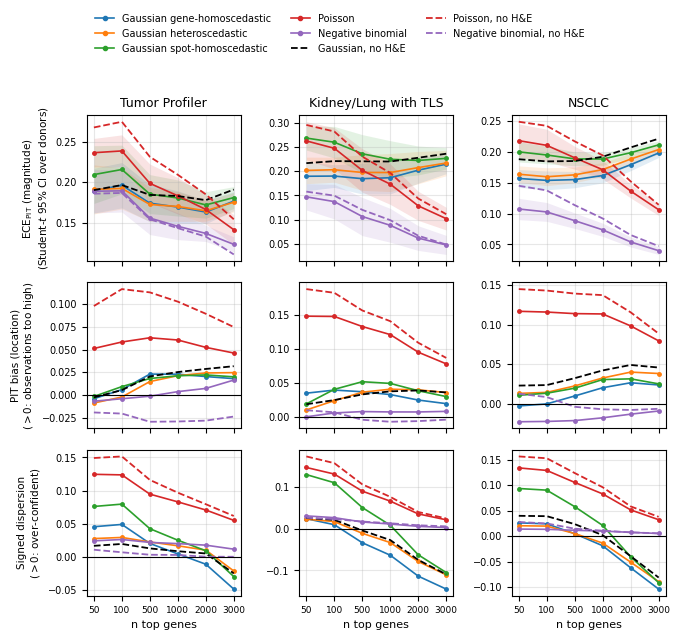

In [4]:
from matplotlib.lines import Line2D

# Canonical model -> color map, keyed on model_type, IDENTICAL to canal1_NLL_selection_classic.ipynb so a
# model keeps one color across every figure of the paper.
MODEL_COLORS = {
    "homoscedastic":                       "#1f77b4",   # blue
    "heteroscedastic":                     "#ff7f0e",   # orange
    "spot_homoscedastic":                  "#2ca02c",   # green
    "poisson_cp":                          "#d62728",   # red    -- Poisson family
    "negativebinomial_hetero_noanchor_cp": "#9467bd",   # purple -- NB family, free dispersion
}
MODEL_LABELS = {
    "homoscedastic":                       "Gaussian gene-homoscedastic",
    "heteroscedastic":                     "Gaussian heteroscedastic",
    "spot_homoscedastic":                  "Gaussian spot-homoscedastic",
    "poisson_cp":                          "Poisson",
    "negativebinomial_hetero_noanchor_cp": "Negative binomial",
}
# Baseline dashed in its family's model color -> the model/baseline pairing is immediate.
# The Gaussian family has three models and no single color, so its baseline is black.
BASELINE_COLORS = {"gaussian": "black", "poisson": "#d62728", "nb": "#9467bd"}
BASELINE_LABELS = {"gaussian": "Gaussian, no H&E", "poisson": "Poisson, no H&E",
                   "nb": "Negative binomial, no H&E"}
DATASET_LABELS = {"10x_TuPro": "Tumor Profiler", "TLS": "Kidney/Lung with TLS",
                  "LUNG_CANCER": "NSCLC"}

# rows of the figure: (metric, y label, draw the donor CI band?)
METRIC_ROWS = [
    ("ece_pit",     "ECE$_\\mathrm{PIT}$ (magnitude)\n(Student-$t$ 95% CI over donors)", True),
    ("pit_bias",    "PIT bias (location)\n($>0$: observations too high)", False),
    ("disp_signed", "Signed dispersion\n($>0$: over-confident)", False),
]

ds_plot = [ds for ds in DATASETS if ds in CURVES]
fig, axes = plt.subplots(3, len(ds_plot), figsize=(6.9, 6.4), sharex="col")

for j, ds in enumerate(ds_plot):
    entry = CURVES[ds]
    x = np.arange(len(entry["ns"]))
    for i, (metric, _ylab, band) in enumerate(METRIC_ROWS):
        ax = axes[i, j]
        for mt in FIG_MODELS:                              # fixed order -> stable colors/legend
            cur = entry["model"].get((mt, metric))
            if cur is None:
                continue
            c = MODEL_COLORS[mt]
            if band:
                ax.fill_between(x, cur["ci_lo"], cur["ci_hi"], color=c, alpha=0.13, linewidth=0)
            ax.plot(x, cur["mean"], "-o", ms=2.5, lw=1.2, color=c)
        for fam in BASE_FAMILIES:
            cur = entry["baseline"].get((fam, metric))
            if cur is None:
                continue
            ax.plot(x, cur["mean"], "--", lw=1.3, color=BASELINE_COLORS[fam])
        if metric != "ece_pit":
            ax.axhline(0, color="black", lw=0.8)
        ax.grid(alpha=0.3)
        ax.tick_params(labelsize=7)
    axes[0, j].set_title(DATASET_LABELS.get(ds, ds), fontsize=9)
    axes[2, j].set_xticks(x)
    axes[2, j].set_xticklabels([str(n) for n in entry["ns"]], fontsize=6.5)
    axes[2, j].set_xlabel("n top genes", fontsize=8)

for i, (_metric, ylab, _band) in enumerate(METRIC_ROWS):
    axes[i, 0].set_ylabel(ylab, fontsize=7.5)

handles = ([Line2D([0], [0], color=MODEL_COLORS[mt], marker="o", ms=3, lw=1.2,
                   label=MODEL_LABELS[mt]) for mt in FIG_MODELS]
           + [Line2D([0], [0], color=BASELINE_COLORS[f], lw=1.3, ls="--",
                     label=BASELINE_LABELS[f]) for f in BASE_FAMILIES])
plt.tight_layout(rect=[0, 0, 1, 0.88])
fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 1.0),
           ncol=3, frameon=False, fontsize=7)

# DISTINCT filename per run, so re-running one notebook can never overwrite another run's figure.
FIG_DIR = PROJ / "results" / "_analysis" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
for ext in ("pdf", "png"):
    fig.savefig(FIG_DIR / f"fig_calibration_{RUN_ID}.{ext}", dpi=300, bbox_inches="tight")
print("written:", f"fig_calibration_{RUN_ID}.pdf")
plt.show()

## 4. Gap model − baseline of the same family, PAIRED by donor

The value histology adds to calibration, with an interval. Pairing is done donor by donor (each donor is its own control), so patient difficulty cancels out and the CI is on the difference.

Two cutoffs: the **full panel** (the number to cite, no selection bias) and **n = 500** (the regime of the best-predicted genes). `Δ < 0` = the H&E model is better calibrated than its no-image baseline. The two restricted-dispersion NB heads are included here.

In [5]:
# The baseline parquet is read ONCE per dataset and pre-pivoted to a (gene x donor) matrix per
# (family, metric) -- paired_gap is called 3 datasets x 2 cutoffs x 8 models x 3 metrics times,
# and re-reading + re-pivoting inside that loop would dominate the cell.
BASE_MAT = {}
for ds in CURVES:
    bl = pd.read_parquet(BASELINE_DIR / f"{ds}.parquet")
    for fam in BASE_FAMILIES:
        sub = bl[bl["family"] == fam]
        if sub.empty:
            continue
        for m in CALIB:
            piv = sub.pivot_table(index="gene", columns="test_donor", values=m)
            piv.columns = piv.columns.astype(str)
            BASE_MAT[(ds, fam, m)] = piv


def paired_gap(ds, model_type, metric, n):
    """Per-donor (model - its family baseline) over the first n ranked genes -> mean + donor CI."""
    order = CURVES[ds]["order"][:n]
    s = next((s for s in summaries if s["dataset"] == ds and s["model_type"] == model_type), None)
    fam = FAMILY_OF.get(model_type)
    if s is None or fam is None or (ds, fam, metric) not in BASE_MAT:
        return None
    if metric not in s["per_long"].columns:
        return None
    mm = gene_donor_matrix(s["per_long"], metric).reindex(order).mean(axis=0, skipna=True)
    mb = BASE_MAT[(ds, fam, metric)].reindex(order).mean(axis=0, skipna=True)
    mm.index = mm.index.astype(str)
    assert set(mm.index) == set(mb.index), f"{ds}/{model_type}: donors not aligned"
    diff = (mm - mb.reindex(mm.index)).dropna()
    st = donor_lopo_stats(diff.to_dict())
    lo, hi = st["ci95_mean"]
    return dict(dataset=ds, model=model_type, family=fam, metric=metric, n=n,
                model_mean=float(mm.mean()), baseline_mean=float(mb.mean()),
                delta=st["mean"], ci_lo=lo, ci_hi=hi,
                excludes_zero=bool(lo > 0 or hi < 0),
                n_donors_better=int((diff < 0).sum()), K=st["K"])


gap_rows = []
for ds in CURVES:
    full = len(CURVES[ds]["order"])
    for n in (500, full):
        for mt in RANK_MODELS:
            for m in CALIB:
                r = paired_gap(ds, mt, m, n)
                if r is not None:
                    gap_rows.append(r)
gaps = pd.DataFrame(gap_rows)

print("=" * 118)
print("PAIRED GAP  model(H&E) − marginal baseline of the SAME family  [95% donor CI on the difference]")
print("  ece_pit: delta < 0 => histology IMPROVES calibration. '*' = CI excluding 0.")
print("  pit_bias / disp_signed: SIGNED quantities -- read the move toward 0, not the sign of the delta.")
print("=" * 118)
for (ds, m, n), sub in gaps.groupby(["dataset", "metric", "n"], sort=False):
    print(f"\n--- {ds} | {m} | n = {n} (K = {int(sub['K'].iloc[0])} donors) ---")
    for _, r in sub.sort_values("delta").iterrows():
        star = "*" if r["excludes_zero"] else " "
        print(f" {star} {r['model']:<38s} model {r['model_mean']:+.4f}  baseline:{r['family']:<8s} "
              f"{r['baseline_mean']:+.4f}  delta {r['delta']:+.4f} [{r['ci_lo']:+.4f},{r['ci_hi']:+.4f}]  "
              f"donors better {int(r['n_donors_better'])}/{int(r['K'])}")

PAIRED GAP  model(H&E) − marginal baseline of the SAME family  [95% donor CI on the difference]
  ece_pit: delta < 0 => histology IMPROVES calibration. '*' = CI excluding 0.
  pit_bias / disp_signed: SIGNED quantities -- read the move toward 0, not the sign of the delta.

--- 10x_TuPro | ece_pit | n = 500 (K = 7 donors) ---
 * poisson_cp                             model +0.1987  baseline:poisson  +0.2314  delta -0.0327 [-0.0615,-0.0040]  donors better 6/7
   heteroscedastic                        model +0.1727  baseline:gaussian +0.1845  delta -0.0118 [-0.0311,+0.0075]  donors better 5/7
   homoscedastic                          model +0.1743  baseline:gaussian +0.1845  delta -0.0102 [-0.0300,+0.0096]  donors better 5/7
   negativebinomial_spotdisp_cp           model +0.1529  baseline:nb       +0.1544  delta -0.0015 [-0.0125,+0.0096]  donors better 4/7
   spot_homoscedastic                     model +0.1854  baseline:gaussian +0.1845  delta +0.0010 [-0.0219,+0.0239]  donors better 3/7

## 5. The expression confounder: what σ encodes, and what the difficulty axis really is

Two quantities, not to be confused:

1. **`sigma_mean_corr`** -- Pearson **across genes** of (the gene's mean predicted σ) against (the gene's expression level), computed per donor then averaged. ~1: σ mostly encodes the gene's expression scale; ~0: σ is decoupled from it.
   ⚠️ **Not comparable across families**: each run is evaluated on ITS own axis (log-CP10k for the Gaussian, count scale for Poisson/NB), cf. `benchmark_summary.py`, docstring of `iter_fold_predictions`. To be read as a within-family statement, never as a ranking.
2. **Spearman(per-gene Pearson, gene expression)** -- this one is comparable, and it is what establishes that the figure's difficulty axis is empirically an expression axis.

In [6]:
from scipy.stats import spearmanr

# --- 5a. sigma_mean_corr, read from each run's benchmark_summary.json (already computed by canal1)
rows = []
for s in summaries + summaries_raw:
    d = RESULTS / s["dataset"] / RUN_ID / s["gene_set"] / RADIUS / s["model_type"]
    if s["lambda_dir"]:
        d = d / s["lambda_dir"]
    js = d / "benchmark_summary.json"
    if not js.is_file():
        continue
    meta = json.loads(js.read_text())
    per_donor = [v for v in meta.get("sigma_mean_corr_per_donor", {}).values() if v is not None]
    if not per_donor or not np.isfinite(meta.get("sigma_mean_corr", np.nan)):
        continue                      # msemeanonly: no predictive variance at all
    rows.append(dict(dataset=s["dataset"], model=s["model_type"],
                     sigma_mean_corr=meta["sigma_mean_corr"],
                     donor_min=float(np.nanmin(per_donor)), donor_max=float(np.nanmax(per_donor)),
                     K=len(per_donor)))
sig = pd.DataFrame(rows)
print("=" * 100)
print("sigma_mean_corr -- Pearson ACROSS GENES of (gene mean sigma) vs (gene expression)")
print("  each run on ITS own axis -> within-family statement, NOT a cross-family ranking.")
print("=" * 100)
if not sig.empty:
    print(sig.pivot_table(index="model", columns="dataset", values="sigma_mean_corr")
             .reindex(RANK_MODELS + RAW_MODELS).dropna(how="all").round(3).to_string())
    print("\nrange over donors (min, max):")
    for _, r in sig.iterrows():
        print(f"  {r['dataset']:<12s} {r['model']:<40s} {r['sigma_mean_corr']:+.3f} "
              f"[{r['donor_min']:+.3f}, {r['donor_max']:+.3f}] over K={int(r['K'])}")

# --- 5b. the difficulty axis IS an expression axis
GENE_EXPR_PARQUET = PROJ / "results" / "_analysis" / "gene_expression_stats.parquet"
assert GENE_EXPR_PARQUET.is_file(), (
    f"missing: {GENE_EXPR_PARQUET}\n-> bash snake/scripts/canals/launch_dataset_gene_expression_stats_precompute.sh")
expr_df = pd.read_parquet(GENE_EXPR_PARQUET)
EXPR_BY_DS = {ds: g.set_index("gene")[["mean_cp10k", "mean_log1p_cp10k", "pct_zeros"]]
              for ds, g in expr_df.groupby("dataset")}

print("\n" + "=" * 100)
print("Spearman per dataset: gene Pearson (averaged over donors) vs expression level / % zeros")
print("  this is what makes the figure's x axis readable as an EXPRESSION REGIME CHANGE.")
print("=" * 100)
conf_rows = []
for ds in CURVES:
    ex = EXPR_BY_DS[ds]
    for s in [s for s in summaries if s["dataset"] == ds]:
        pg = gene_donor_matrix(s["per_long"], "pearson").mean(axis=1)
        common = pg.index.intersection(ex.index)
        conf_rows.append(dict(
            dataset=ds, model=s["model_type"], n_genes=len(common),
            rho_expr=spearmanr(pg.loc[common], ex.loc[common, "mean_log1p_cp10k"]).correlation,
            rho_zeros=spearmanr(pg.loc[common], ex.loc[common, "pct_zeros"]).correlation))
    # the ranking axis itself (cross-model), i.e. exactly the figure's x-axis. rank_score is a
    # DECREASING rank (best-predicted gene first), so a positive rho means "genes that come first
    # on the figure's x-axis are the more expressed ones".
    rank_score = pd.Series(np.arange(len(CURVES[ds]["order"]), 0, -1), index=CURVES[ds]["order"])
    common = rank_score.index.intersection(ex.index)
    conf_rows.append(dict(
        dataset=ds, model="FIGURE AXIS (cross-model)", n_genes=len(common),
        rho_expr=spearmanr(rank_score.loc[common], ex.loc[common, "mean_log1p_cp10k"]).correlation,
        rho_zeros=spearmanr(rank_score.loc[common], ex.loc[common, "pct_zeros"]).correlation))
conf = pd.DataFrame(conf_rows)
print(conf.pivot_table(index="model", columns="dataset", values="rho_expr").round(3).to_string())
print("\nsame thing against the % zeros (expected: opposite sign):")
print(conf.pivot_table(index="model", columns="dataset", values="rho_zeros").round(3).to_string())

sigma_mean_corr -- Pearson ACROSS GENES of (gene mean sigma) vs (gene expression)
  each run on ITS own axis -> within-family statement, NOT a cross-family ranking.
dataset                               10x_TuPro  LUNG_CANCER    TLS
model                                                              
homoscedastic                             0.731        0.829  0.691
heteroscedastic                           0.732        0.801  0.738
spot_homoscedastic                        0.000       -0.000  0.000
poisson_cp                                0.665        0.688  0.639
negativebinomial_hetero_noanchor_cp       0.714        0.745  0.796
negativebinomial_spotdisp_cp              0.638        0.649  0.618
negativebinomial_genedisp_cp              0.821        0.795  0.824
poisson_raw                               0.640        0.660  0.643
negativebinomial_hetero_noanchor_raw      0.649        0.755  0.806

range over donors (min, max):
  10x_TuPro    heteroscedastic                          

## 6. Depth-blind models (`*_raw`) -- separate table

Their **correlation** lives on `log1p(raw counts)` and must never share an axis with the `_cp`/Gaussian ones. Their **PIT triple**, however, is comparable: the PIT is uniform on [0,1] by construction whatever the target scale. They are therefore reported here, on the full shared panel, **without a baseline** (the marginal baseline is fitted on the `cp` target, which is not their reference).

In [7]:
if summaries_raw:
    stats_raw, _ = headline_registry(summaries_raw, metrics=CALIB)
    print(format_headline_registry(stats_raw, datasets=DATASETS, metrics=CALIB))

    # Side-by-side with their _cp twin: same likelihood, same architecture, different target.
    TWINS = {"poisson_raw": "poisson_cp",
             "negativebinomial_hetero_noanchor_raw": "negativebinomial_hetero_noanchor_cp"}
    print("\n" + "=" * 100)
    print("raw vs its cp twin -- full shared panel, mean over donors (PIT only)")
    print("=" * 100)
    both = pd.concat([stats.assign(axis="log1p(CP10k)"), stats_raw.assign(axis="log1p(raw counts)")])
    both["model_type"] = both["model"].str.split("|").str[0]
    keep = set(TWINS) | set(TWINS.values())
    tbl = (both[both["model_type"].isin(keep)]
           .pivot_table(index=["model_type", "axis"], columns=["dataset", "metric"], values="mean"))
    print(tbl.round(4).to_string())
else:
    print("no *_raw run found under", RESULTS.relative_to(PROJ))

HEADLINE -- full shared gene panel. THREE DIFFERENT THINGS, do not swap them:
  SE / t-CI     spread of the MEAN over donors (patients resampled, gene panel fixed).
                One estimand, two presentations: t-CI = mean +/- t*·SE.  <- THE headline bar.
  PI-new-donor  where a NEW patient would land. Wider, and a different question entirely.
  gene-boot     genes resampled, donor cohort FIXED -> ZERO inter-donor variance.
                Gene-panel stability only; far narrower (N genes vs K donors).
LOPO folds share K-2 training donors (Bengio & Grandvalet 2004), so these intervals are
optimistic -- always read them next to the per-donor points (donor_points).

--- 10x_TuPro | ece_pit  (K=7 donors, N=3000 genes) ---
  poisson_raw                                +0.1450  SE 0.0051  t-CI [+0.1324,+0.1576] (df 6, t* 2.45)  PI-new-donor [+0.1094,+0.1806]  gene-boot [+0.1419,+0.1482] (SE 0.0016)
  negativebinomial_hetero_noanchor_raw       +0.1241  SE 0.0057  t-CI [+0.1103,+0.1379] (df 